# 02 · Manifold — topology test & principal-curve trajectory

Wang 2019's glioblastoma malignant manifold is tested **honestly for branching** before any
trajectory is committed. A scFates PPT **tree** is fit first and its branch nodes inspected on
the embedding: the fork count *scales with node resolution* (5 forks at 30 nodes → 18 at 100)
and the forks scatter throughout the 2-D cloud rather than resolving one stable Y — the
signature of over-segmenting a continuous cloud, not a genuine bifurcation. Consistent with
this, the two putative "arm" signatures **Gast and pSom co-vary** (they do not diverge). The
correct topology is therefore a **principal curve** (ElPiGraph, non-branching by construction)
fit on the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic compartment
fabricates folds). The developmental signatures (Gast / pSom / neural-crest) are scored against
the shared **union** control pool and graph-smoothed to read geography over 10x dropout.

**Scope decision (derived).** Cell cycle is *orthogonal* to the developmental axis here
(cycling fraction is uniform across lobes and cycling barely correlates with any signature),
so — unlike Kürten's low-cycling-lobe scoping — the **whole manifold** is the honest
developmental object (Bischoff / Sun / Lee no-scoping precedent). The curve is rooted at the
gastrulation/somitogenesis-high tip and pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells keep their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the
shared **union** control pool and graph-smoothed (3× kNN-connectivity averaging) to read
geography rather than per-cell 10x dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean {adata.obs[lab].mean():+.4f}')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 9634 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.45
Gast: 77/81 genes present | mean -0.0025
pSom: 92/98 genes present | mean +0.0077
Crest: 100/104 genes present | mean -0.0073


### Branching honesty test — PPT tree
Fit a scFates PPT **tree** and count branch nodes across a node/sigma sweep. A genuine
bifurcation gives one stable fork whose two arms carry *opposing* signatures. Here the fork
count grows monotonically with node resolution and the forks are distributed throughout the
cloud — the hallmark of over-branching a continuous 2-D manifold, not a real Y.

In [4]:
def tree_topo(a):
    B = np.asarray(a.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree branch-node sweep (fork count should be stable for a real bifurcation):')
for Nodes in [30, 50, 100]:
    aa = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(aa, method='ppt', Nodes=Nodes, ppt_lambda=100, ppt_sigma=0.1,
                    use_rep='X_umap', seed=SEED, plot=False, basis='umap')
    tips, forks = tree_topo(aa)
    print(f'  Nodes={Nodes}: tips={tips} forks={forks}')
print('-> fork count scales with resolution (not one stable Y) => continuous cloud, not a bifurcation')

PPT tree branch-node sweep (fork count should be stable for a real bifurcation):
  Nodes=30: tips=7 forks=5
  Nodes=50: tips=13 forks=10
  Nodes=100: tips=20 forks=18
-> fork count scales with resolution (not one stable Y) => continuous cloud, not a bifurcation


### Render the PPT tree over the developmental signatures
The tree edges (black) with fork nodes (red stars) drawn over the smoothed Gast/pSom/Crest
maps: the two "arm" candidates Gast and pSom do **not** occupy opposing arms of a single fork
— they co-vary — while Crest occupies the opposite end. No branch separates a Gast arm from a
pSom arm.

Gast & pSom co-vary; the scattered forks do not separate a Gast arm from a pSom arm -> non-branching


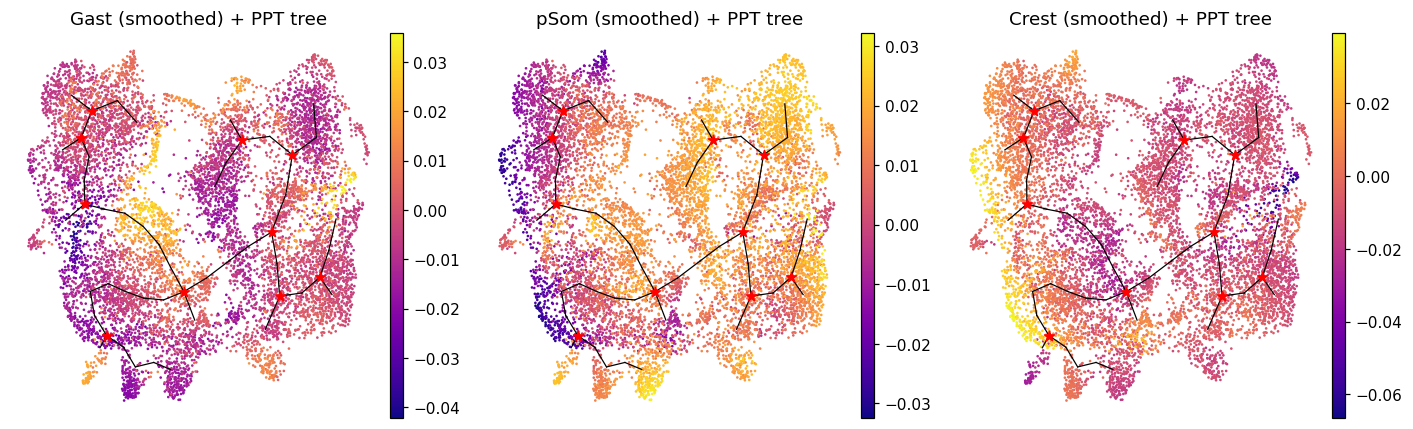

In [5]:
aa = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(aa, method='ppt', Nodes=50, ppt_lambda=100, ppt_sigma=0.1,
                use_rep='X_umap', seed=SEED, plot=False, basis='umap')
B = np.asarray(aa.uns['graph']['B']); F = aa.uns['graph']['F'].T
fig, axes = plt.subplots(1, 3, figsize=(13,4))
for ax,(m,ti) in zip(axes, [('Gast_sm','Gast'),('pSom_sm','pSom'),('Crest_sm','Crest')]):
    sc.pl.umap(aa, color=m, size=12, frameon=False, show=False, ax=ax, cmap='plasma', title=ti+' (smoothed) + PPT tree')
    ii,jj = np.where(np.triu(B>0))
    for a_,b_ in zip(ii,jj): ax.plot([F[a_,0],F[b_,0]],[F[a_,1],F[b_,1]],'k-',lw=.8,zorder=10)
    deg=(B>0).sum(0)
    ax.scatter(F[deg>=3,0],F[deg>=3,1],c='red',s=45,marker='*',zorder=11)
fig.tight_layout()
print('Gast & pSom co-vary; the scattered forks do not separate a Gast arm from a pSom arm -> non-branching')

### Scope decision — whole manifold vs a low-cycling lobe (data-driven)
Test whether the developmental axis is confined to a low-cycling lobe (Kürten case, scoping
justified) or spans the whole manifold (Bischoff/Sun/Lee case). Two facts settle it: (i) the
smoothed developmental signatures co-vary as one axis (Gast↔pSom positive, both opposite
Crest); (ii) cycling fraction is uniform across lobes and cell-cycle score barely correlates
with any signature — proliferation is *orthogonal* to the developmental axis, so excluding a
"cycling lobe" would not clean the gradient. Keep the whole manifold.

In [6]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
adata.obs['cyc'] = np.maximum(adata.obs['S_score'].astype(float), adata.obs['G2M_score'].astype(float))
print('\nper-lobe smoothed developmental means + cycling fraction + cell-cycle score:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling','cyc']].mean().round(4).to_string())
print('\ncell-cycle score vs developmental signatures (orthogonality check):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  corr({m}, cyc) = {np.corrcoef(adata.obs[m], adata.obs["cyc"])[0,1]:+.2f}')
print('-> developmental axis orthogonal to proliferation; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.16
  Crest_sm vs Gast_sm: r = -0.49
  Crest_sm vs pSom_sm: r = -0.87

per-lobe smoothed developmental means + cycling fraction + cell-cycle score:
      Gast_sm  pSom_sm  Crest_sm  cycling     cyc
lobe                                             
0     -0.0036  -0.0020    0.0016   0.2283 -0.0139
1     -0.0041   0.0052   -0.0043   0.2834 -0.0107
2     -0.0037   0.0151   -0.0121   0.2144 -0.0058

cell-cycle score vs developmental signatures (orthogonality check):
  corr(Gast_sm, cyc) = -0.07
  corr(pSom_sm, cyc) = +0.08
  corr(Crest_sm, cyc) = -0.08
-> developmental axis orthogonal to proliferation; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. The fold diagnostic reports
a node self-approach ratio (minimum distance between graph-non-adjacent nodes, in units of
median edge length): a ratio > 1 certifies the curve does not fold back on itself. `epg_mu=100`
is strong bending regularisation, keeping the arc smooth rather than a sharp V. The topology is
robust across Nodes 15/20/30 (2 tips, 0 forks, ratio ~2.4–3.0).

In [7]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve: 2 tips, 0 forks | fold self-approach ratio = 2.80 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin (neural crest is developmentally *late*, so it is the terminus, never the root).
Pseudotime then flows to the neural-crest terminus.

In [8]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm','cyc']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0052 pSom=-0.0020 Crest=+0.0021
tip 2: Gast=-0.0025 pSom=+0.0150 Crest=-0.0127
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.054 p=1.1e-07
  pSom_sm: rho=-0.614 p=0.0e+00
  Crest_sm: rho=+0.489 p=0.0e+00
  cyc: rho=+0.039 p=1.2e-04


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis can
silently reflect an axis). This manifold is already **horizontal** in the raw embedding, so the
house transform is the **identity** with at most a horizontal flip to put low pseudotime on the
left. The assertion confirms low pseudotime lands on the left.

In [9]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                   # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: horizontal flip to low-pt-left; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: horizontal flip to low-pt-left; corr(x_lin, pseudotime) = +0.97


### Curve render + save (deliverable)
The committed curve edges (black) are drawn over pseudotime to confirm the fold-free backbone
visually, then the house-style `manifold.pdf` (pseudotime, cividis, `figsize=(3.5,1.5)`) is
saved.

curve is fold-free (2 tips, 0 forks); root = lime star at the Gast/pSom-high origin


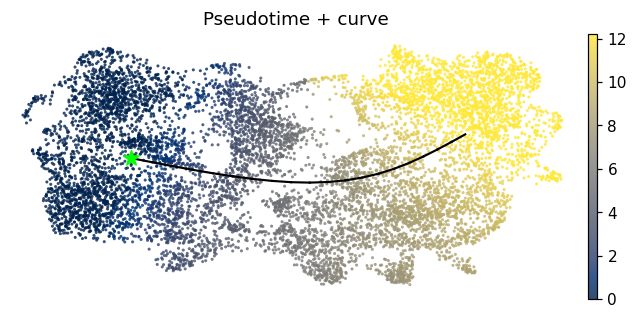

In [10]:
# render curve edges over pseudotime on the linear layout
Bc = np.asarray(sub.uns['graph']['B']); Fc = sub.uns['graph']['F'].T
# map node coords through the same orientation transform
Fx = Fc.copy()
if float(np.corrcoef(sub.obsm['X_umap'][:,0], sub.obs['t'])[0,1]) < 0:
    Fx[:,0] = -Fx[:,0]
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(6,3))
sc.pl.umap(plot, color='t', cmap='cividis', size=16, alpha=.8, frameon=False, show=False, ax=ax, title='Pseudotime + curve')
ii,jj = np.where(np.triu(Bc>0))
for a_,b_ in zip(ii,jj): ax.plot([Fx[a_,0],Fx[b_,0]],[Fx[a_,1],Fx[b_,1]],'k-',lw=1.4,zorder=10)
ax.scatter(Fx[root,0],Fx[root,1],c='lime',s=110,marker='*',zorder=12)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()
print('curve is fold-free (2 tips, 0 forks); root = lime star at the Gast/pSom-high origin')

saved manifold.h5ad + manifold.pdf


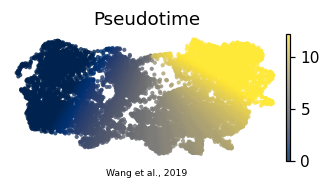

In [11]:
# sanitize non-serializable ElPiGraph uns entry
if 'epg' in sub.uns:
    try: sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
    except Exception: sub.uns['epg'] = {}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')